# Day 27 — Product Analysis
Project 1: Retail Sales & Customer Performance Analysis

Objective: Which products are driving revenue and profit? Source: Institute Day 27 assignment and Day 24 transformed dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
sns.set_theme(style='whitegrid')
Path('charts').mkdir(exist_ok=True)
df = pd.read_csv('transformed_retail_sales.csv', parse_dates=['Order_Date'])
print('Shape:', df.shape)
display(df.head())
revenue = df.Sales.sum()
p = df.groupby(['Category','Product'], as_index=False).agg(Sales=('Sales','sum'), Orders=('Order_ID','nunique'), Quantity=('Quantity','sum')).sort_values('Sales',ascending=False).reset_index(drop=True)
p['Revenue_Contribution_Pct'] = 100*p.Sales/revenue
p['Average_Order_Value'] = p.Sales/p.Orders
p['Revenue_Rank'] = p.Sales.rank(method='min',ascending=False).astype(int)
p['Profit'] = float('nan')
p['Profit_Margin'] = float('nan')
p['Decline_Status'] = 'Unavailable: one month'
display(p)

Shape: (30, 27)


,Order_ID,Order_Date,Customer_Name,City,Category,Product,Quantity,Unit_Price,Sales,Customer_Rating,Customer_Rating_Was_Imputed,Year,Month,Month_Name,Quarter,Profit_Margin,Order_Value,Customer_Total_Spending,Customer_Segment,Sales_Category,Customer_Order_Count,Customer_Type,Product_Total_Sales,Product_Performance,Order_Size,Day_Name,Is_Weekend
0,ORD001,2026-10-02,Rahul,Mumbai,Clothing,T-Shirt,2,650,1300,5.0,False,2026,10,October,4,NaN,1300,13350,Medium Value,Medium,5,Repeat,14950,Low,Small,Friday,False
1,ORD002,2026-10-03,Neha,Nagpur,Grocery,Rice,3,320,960,3.0,False,2026,10,October,4,NaN,960,10700,Medium Value,Low,5,Repeat,6720,Low,Medium,Saturday,True
2,ORD003,2026-10-04,Vikram,Nashik,Home,Lamp,4,1100,4400,4.0,False,2026,10,October,4,NaN,4400,13350,Medium Value,High,5,Repeat,24200,High,Medium,Sunday,True
3,ORD004,2026-10-05,Priya,Pune,Electronics,Headphones,5,1500,7500,5.0,False,2026,10,October,4,NaN,7500,17780,High Value,High,5,Repeat,36000,High,Large,Monday,False
4,ORD005,2026-10-06,Arjun,Pune,Clothing,T-Shirt,1,650,650,4.0,False,2026,10,October,4,NaN,650,12450,Medium Value,Low,5,Repeat,14950,Low,Small,Tuesday,False


,Category,Product,Sales,Orders,Quantity,Revenue_Contribution_Pct,Average_Order_Value,Revenue_Rank,Profit,Profit_Margin,Decline_Status
0,Electronics,Headphones,36000,7,24,43.972151,5142.857143,1,NaN,NaN,Unavailable: one month
1,Home,Lamp,24200,7,22,29.559057,3457.142857,2,NaN,NaN,Unavailable: one month
2,Clothing,T-Shirt,14950,8,23,18.260657,1868.750000,3,NaN,NaN,Unavailable: one month
3,Grocery,Rice,6720,8,21,8.208135,840.000000,4,NaN,NaN,Unavailable: one month


## Task 1 — Top 10 products by sales
Only four products exist; return all available products.

In [2]:
top=p.nlargest(10,'Sales'); display(top); top.to_csv('top_10_products.csv',index=False)

,Category,Product,Sales,Orders,Quantity,Revenue_Contribution_Pct,Average_Order_Value,Revenue_Rank,Profit,Profit_Margin,Decline_Status
0,Electronics,Headphones,36000,7,24,43.972151,5142.857143,1,NaN,NaN,Unavailable: one month
1,Home,Lamp,24200,7,22,29.559057,3457.142857,2,NaN,NaN,Unavailable: one month
2,Clothing,T-Shirt,14950,8,23,18.260657,1868.750000,3,NaN,NaN,Unavailable: one month
3,Grocery,Rice,6720,8,21,8.208135,840.000000,4,NaN,NaN,Unavailable: one month


## Task 2 — Bottom 10 products
Low revenue is not evidence of low profitability.

In [3]:
bottom=p.nsmallest(10,'Sales'); display(bottom); bottom.to_csv('bottom_10_products.csv',index=False)

,Category,Product,Sales,Orders,Quantity,Revenue_Contribution_Pct,Average_Order_Value,Revenue_Rank,Profit,Profit_Margin,Decline_Status
3,Grocery,Rice,6720,8,21,8.208135,840.000000,4,NaN,NaN,Unavailable: one month
2,Clothing,T-Shirt,14950,8,23,18.260657,1868.750000,3,NaN,NaN,Unavailable: one month
1,Home,Lamp,24200,7,22,29.559057,3457.142857,2,NaN,NaN,Unavailable: one month
0,Electronics,Headphones,36000,7,24,43.972151,5142.857143,1,NaN,NaN,Unavailable: one month


## Task 3 — Most profitable products
Profit DESC cannot be evaluated: no actual profit or cost field. Blank values are unknown, not zero.

In [4]:
print('Profit available:', 'Profit' in df.columns and df.get('Profit',pd.Series(dtype=float)).notna().any())

Profit available: False


## Task 4 — Low-margin products
High sales plus low profit margin cannot be identified without actual margin data.

In [5]:
print('Available profit margin observations:', df.Profit_Margin.notna().sum())

Available profit margin observations: 0


## Task 5 — Declining products
Compare monthly revenue. Consistent decline requires multiple months; one observed month cannot establish a trend.

In [6]:
monthly=df.assign(Month=df.Order_Date.dt.to_period('M').astype(str)).pivot_table(index='Month',columns='Product',values='Sales',aggfunc='sum'); display(monthly); print('Observed months:',len(monthly)); monthly.to_csv('monthly_product_sales.csv')

Product,Headphones,Lamp,Rice,T-Shirt
Month,,,,
2026-10,36000,24200,6720,14950


Observed months: 1


## Task 6 — Category performance
Calculate sales and distinct orders; profit and margin remain unavailable.

In [7]:
cat=df.groupby('Category',as_index=False).agg(Sales=('Sales','sum'),Orders=('Order_ID','nunique'),Quantity=('Quantity','sum')).sort_values('Sales',ascending=False)
cat['Profit']=float('nan'); cat['Profit_Margin']=float('nan')
display(cat)
cat.to_csv('category_performance.csv',index=False)
p.to_csv('Product_Performance.csv',index=False)
assert p.Sales.sum()==cat.Sales.sum()==revenue
assert p.Quantity.sum()==df.Quantity.sum()
assert abs(p.Revenue_Contribution_Pct.sum()-100)<1e-8
print('Revenue, quantity and contribution checks passed:',revenue)

,Category,Sales,Orders,Quantity,Profit,Profit_Margin
1,Electronics,36000,7,24,NaN,NaN
3,Home,24200,7,22,NaN,NaN
0,Clothing,14950,8,23,NaN,NaN
2,Grocery,6720,8,21,NaN,NaN


Revenue, quantity and contribution checks passed: 81870


## Additional visualizations and business interpretations

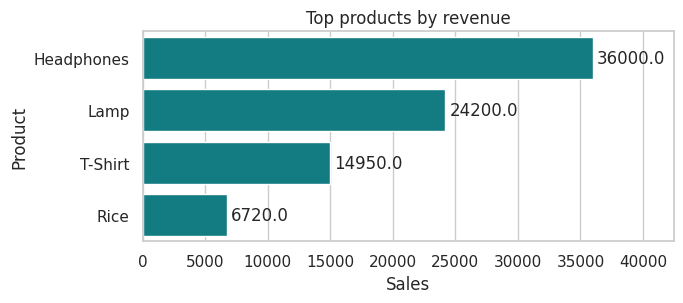

In [8]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=p, x='Sales', y='Product', color='#008C95', ax=ax)
ax.set_title('Top products by revenue'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/01_top.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Headphones leads revenue at INR 36,000.

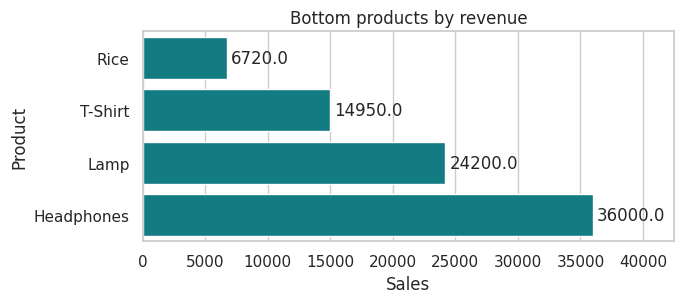

In [9]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=bottom, x='Sales', y='Product', color='#008C95', ax=ax)
ax.set_title('Bottom products by revenue'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/02_bottom.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Rice has the lowest revenue at INR 6,720; investigate demand and pricing.

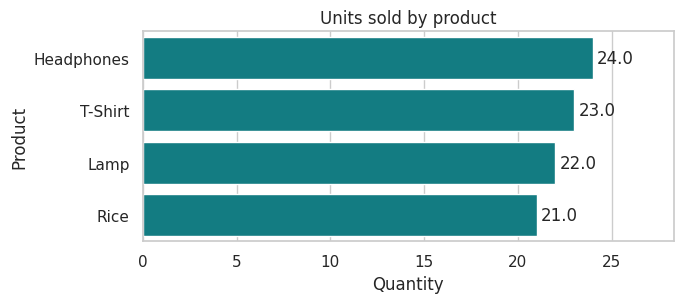

In [10]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=p.sort_values("Quantity",ascending=False), x='Quantity', y='Product', color='#008C95', ax=ax)
ax.set_title('Units sold by product'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/03_quantity.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Headphones leads unit volume with 24 units; volume and revenue are different measures.

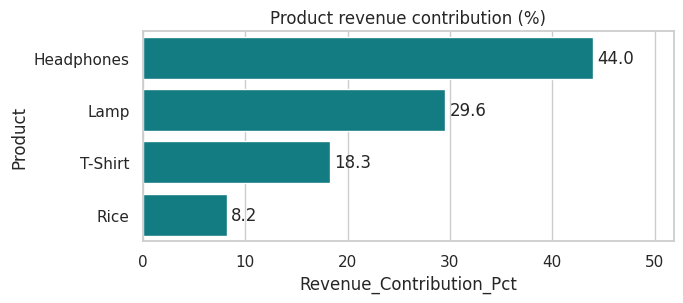

In [11]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=p, x='Revenue_Contribution_Pct', y='Product', color='#008C95', ax=ax)
ax.set_title('Product revenue contribution (%)'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/04_contribution.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Headphones contributes 43.97% of revenue.

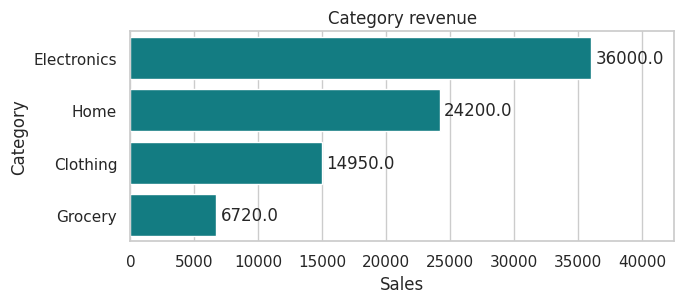

In [12]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=cat, x='Sales', y='Category', color='#008C95', ax=ax)
ax.set_title('Category revenue'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/05_category.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Electronics leads category revenue. Each category contains one observed product.

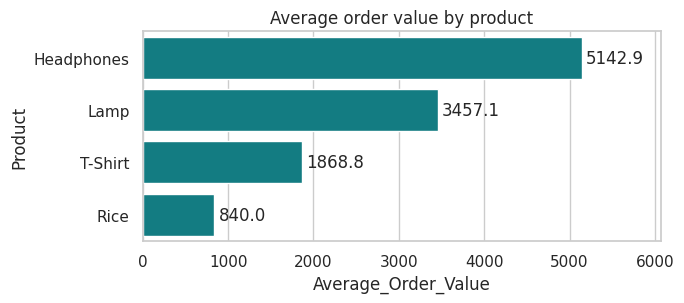

In [13]:
fig, ax = plt.subplots(figsize=(7,3.2))
sns.barplot(data=p.sort_values("Average_Order_Value",ascending=False), x='Average_Order_Value', y='Product', color='#008C95', ax=ax)
ax.set_title('Average order value by product'); ax.bar_label(ax.containers[0], fmt='%.1f', padding=3); ax.margins(x=.18)
fig.tight_layout(); fig.savefig('charts/06_aov.png',dpi=150); plt.show(); plt.close(fig)

**Interpretation:** Headphones has the highest average order value at INR 5,142.86.

## Business recommendations
Prioritize availability of the revenue leader while checking margins before expanding stock. Investigate the lowest-revenue product using price, volume and inventory data. Collect actual cost/profit and multiple months of history before margin or decline decisions. Product names are proxies for missing Product_ID; results cover October 2026 only.